In [12]:
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import pandas as pd
from scipy.constants import pi

In [13]:
###Helper

from pathlib import Path


def save_plot(fig, filename):
    output_dir = Path("plots")
    output_dir.mkdir(exist_ok=True)
    print("Saved a figure")
    fig.savefig(output_dir / f"{filename}.pdf", bbox_inches="tight", transparent=True)


def plot_loglog(x, y, label_x, label_y, ax=None, color=None, label=""):
    if ax is None:
        fig, ax = plt.subplots()
    if color == None:
        ax.plot(x, y, "o", label=label)
    else:
        ax.plot(x, y, "o", c=color, label=label)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(label_x)
    ax.set_ylabel(label_y)
    if label != "":
        ax.legend()
    return ax

### a)

In [14]:
def a(scherrate, scherviskositaet, filename="viscosity_fit"):
    fig, ax = plt.subplots()
    ax.plot(scherrate, scherviskositaet, "o")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"shear rate $\dot \gamma$ [s$^{-1}$]")
    ax.set_ylabel(r"shear viscosity $\eta$ [Pa$\cdot$s]")
    #nullscher_cross, kappa_cross = fit_cross(scherrate, scherviskositaet, ax)
    nullscher_carr, kappa_carr = fit_carreau(scherrate, scherviskositaet, ax)
    ax.legend()
    save_plot(fig, filename)
    print(f"""
 Nullscher: {nullscher_carr}
 kappa {kappa_carr}""")


def cross(scherrate, n, kappa, nullscherviskositaet, hochscherviskositaet):
    return hochscherviskositaet + (nullscherviskositaet - hochscherviskositaet) / (1 + (kappa * scherrate) ** n)


def carreau(scherrate, n, kappa, nullscherviskositaet, hochscherviskositaet):
    return hochscherviskositaet + (nullscherviskositaet - hochscherviskositaet) / (
            (1 + (kappa * scherrate) ** 2) ** (n / 2))


def fit_cross(scherrate, scherviskositaet, ax):
    opt, cov = curve_fit(cross, scherrate, scherviskositaet)
    ax.plot(scherrate, cross(scherrate, *opt), label=rf"""fit according to the cross model
    $n={np.format_float_scientific(opt[0], 3)}$
    $\kappa={np.format_float_scientific(opt[1], 3)}$ s
    $\eta_0={np.format_float_scientific(opt[2], 3)}$ Pa$\cdot$s
    $\eta_\infty={np.format_float_scientific(opt[3], 3)}$ Pa$\cdot$s""")
    return opt[-2,], opt[1]


def fit_carreau(scherrate, scherviskositaet, ax):
    opt, cov = curve_fit(carreau, scherrate, scherviskositaet)
    print(opt, np.sqrt(np.diag(cov)))
    ax.plot(scherrate, carreau(scherrate, *opt), label=rf"""fit according to the carreau model
    $n={np.format_float_scientific(opt[0], 3)}$
    $\kappa={np.format_float_scientific(opt[1], 3)}$ s
    $\eta_0={np.format_float_scientific(opt[2], 3)}$ Pa$\cdot$s
    $\eta_\infty={np.format_float_scientific(opt[3], 3)}$ Pa$\cdot$s""")
    return opt[-2,], opt[1]

### b)

In [15]:
def b(gamma1, gamma7, schubspannung1, schubspannung7, g11, g21, g17, g27, lvr, filename="moduli"):
    y_label = r"storage and loss modulus $G^{\prime}$ & $G^{\prime\prime}$ [Pa]"
    ax_1_gamma = plot_loglog(gamma1, g11, r"deformation $\gamma$", y_label, label="storage modulus at 1 Hz")
    plot_loglog(gamma1, g21, r"deformation $\gamma$ [-]", y_label, ax=ax_1_gamma, label="loss modulus at $1$ Hz")
    ax_7_gamma = plot_loglog(gamma7, g17, r"deformation $\gamma$", y_label, label="storage modulus at 7 Hz")
    plot_loglog(gamma7, g27, r"deformation $\gamma$", y_label, ax=ax_7_gamma, label="loss modulus at 7 Hz")

    ax_1_gamma.axvline(lvr[0], label="cutoff point of the lvr", color="red")
    ax_1_gamma.legend()
    save_plot(ax_1_gamma.figure, f"{filename}_1hz_deformation")

    ax_7_gamma.axvline(lvr[1], label="cutoff point of the lvr", color="red")
    ax_7_gamma.legend()
    save_plot(ax_7_gamma.figure, f"{filename}_7hz_deformation")

    ax_1_omega = plot_loglog(schubspannung1, g11, r"shear stress $\sigma$", y_label, label="storage modulus at 1 Hz")
    plot_loglog(schubspannung1, g21, r"shear stress $\sigma$", y_label, ax=ax_1_omega, label="loss modulus at 1 Hz")
    ax_7_omega = plot_loglog(schubspannung7, g17, r"shear stress $\sigma$", y_label, label="storage modulus at 7 Hz")
    plot_loglog(schubspannung7, g27, r"shear stress $\sigma$", y_label, ax=ax_7_omega, label="loss modulus at 7 Hz")

    save_plot(ax_1_omega.figure, f"{filename}_1hz_stress")
    save_plot(ax_7_omega.figure, f"{filename}_7hz_stress")

    return ax_1_gamma, ax_7_gamma, ax_1_omega, ax_7_omega

### c)

In [36]:
import numpy as np
from scipy.optimize import curve_fit


def maxwell1(omega, tau, g0):
    return g0 * (omega * tau) ** 2 / (1 + (omega * tau) ** 2)


def maxwell2(omega, tau, g0):
    return g0 * (omega * tau) / (1 + (omega * tau) ** 2)


def c(frequenz, g1, g2, lvr_index, filename="maxwell_fit"):
    frequenz = np.asarray(frequenz, dtype=float)
    g1 = np.asarray(g1, dtype=float)
    g2 = np.asarray(g2, dtype=float)

    winkelfrequenz = 2 * np.pi * frequenz
    omega_fit = winkelfrequenz[:lvr_index]
    g1_data = g1[:lvr_index]
    g2_data = g2[:lvr_index]

    ax = plot_loglog(
        omega_fit,
        g1_data,
        r"Angular frequency $\omega$ [rad$\cdot$s$^{-1}$]",
        r"Modulus $G^\prime, G^{\prime\prime}$ [Pa]",
        label=r"Storage modulus $G^\prime$ (fit range)"
    )
    plot_loglog(
        winkelfrequenz[lvr_index:],
        g1[lvr_index:],
        r"Angular frequency $\omega$ [rad$\cdot$s$^{-1}$]",
        r"Modulus $G^\prime, G^{\prime\prime}$ [Pa]",
        color="grey",
        ax=ax,
        label="Points not used in the fit"
    )
    plot_loglog(
        omega_fit,
        g2_data,
        r"Angular frequency $\omega$ [rad$\cdot$s$^{-1}$]",
        r"Modulus $G^\prime, G^{\prime\prime}$ [Pa]",
        ax=ax,
        label=r"Loss modulus $G^{\prime\prime}$ (fit range)"
    )
    plot_loglog(
        winkelfrequenz[lvr_index:],
        g2[lvr_index:],
        r"Angular frequency $\omega$ [rad$\cdot$s$^{-1}$]",
        r"Modulus $G^\prime, G^{\prime\prime}$ [Pa]",
        ax=ax,
        color="grey"
    )

    opt_g1, cov_g1 = curve_fit(
        maxwell1,
        omega_fit,
        g1_data,
        p0=[0.1, 1.5 * np.max(g1_data)],
        bounds=([1e-10, 1e-10], [np.inf, np.inf]),
        maxfev=20000
    )
    opt_g2, cov_g2 = curve_fit(
        maxwell2,
        omega_fit,
        g2_data,
        p0=[0.1, 1.5 * np.max(g2_data)],
        bounds=([1e-10, 1e-10], [np.inf, np.inf]),
        maxfev=20000
    )

    omega_model = np.geomspace(omega_fit[0], omega_fit[-1], 200)
    true_cov_1 = np.sqrt(np.diag(cov_g1))
    true_cov_2 = np.sqrt(np.diag(cov_g2))
    ax.plot(omega_model, maxwell1(omega_model, *opt_g1), "--", label=r"Maxwell fit $G^\prime$")
    ax.plot(omega_model, maxwell2(omega_model, *opt_g2), "--", label=r"Maxwell fit $G^{\prime\prime}$")
    ax.legend()
    save_plot(ax.figure, filename)

    tau_g1, g0_g1 = opt_g1
    tau_g2, g0_g2 = opt_g2
    print(true_cov_1)
    print(f"""
Independent Maxwell fits
------------------------
G':  tau = {tau_g1:.5f} +- {true_cov_1[0]:.5f}s, G0 = {g0_g1:.3f}  +- {true_cov_1[1]:.5f} Pa, eta0 = {tau_g1 * g0_g1:.3f} Pa s
G'': tau = {tau_g2:.5f}  +- {true_cov_2[0]:.5f}s, G0 = {g0_g2:.3f} Pa +- {true_cov_2[1]:.5f}, eta0 = {tau_g2 * g0_g2:.3f} Pa s
""")

    return (opt_g1, cov_g1), (opt_g2, cov_g2)


### d)

In [17]:
def cole(g1, g0):
    return np.sqrt(g1 * (g0 - g1))


def d(g1, g2, g1d, g2d, filename="cole_cole"):
    fig, ax = plt.subplots()
    ax.scatter(g1, g2)
    ax.scatter(g1d, g2d, c="grey", label="data points not used in the fit")
    ax.set_xlabel(r"storage modulus  G$^\prime$ [Pa]")
    ax.set_ylabel(r"loss modulus G$^{\prime\prime}$ [Pa]")

    opt, cov = curve_fit(cole, g1, g2, p0=[2 * np.max(g1)])
    print(f"G0 cole {opt[0]} {np.sqrt(np.diag(cov))}")

    x = np.linspace(g1[0], opt[0], 100, )
    calc_g2 = cole(x, opt[0])

    ax.plot(x, calc_g2, label="cole-cole-plot", color="red")
    ax.legend()
    save_plot(fig, filename)



[1.14156057 0.0575239  3.43949268 0.25400359] [0.08110928 0.00260658 0.00720294 0.04695916]
Saved a figure

 Nullscher: 3.4394926788903692
 kappa 0.05752389808748947
Saved a figure
Saved a figure
Saved a figure
Saved a figure
Saved a figure
[0.01818616 2.90646638]

Independent Maxwell fits
------------------------
G':  tau = 0.09388 +- 0.01819s, G0 = 31.491  +- 2.90647 Pa, eta0 = 2.956 Pa s
G'': tau = 0.05508  +- 0.00076s, G0 = 59.562 Pa +- 0.44908, eta0 = 3.281 Pa s

G0 cole 55.746556453220855 [1.09165762]
Saved a figure
Saved a figure


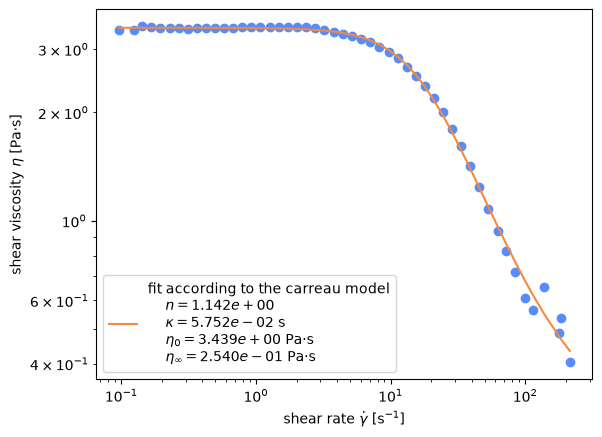

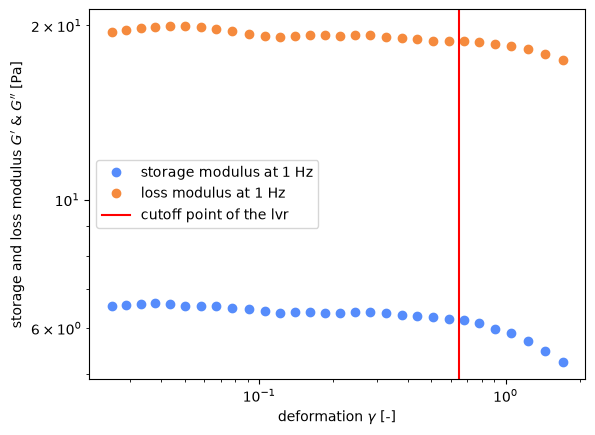

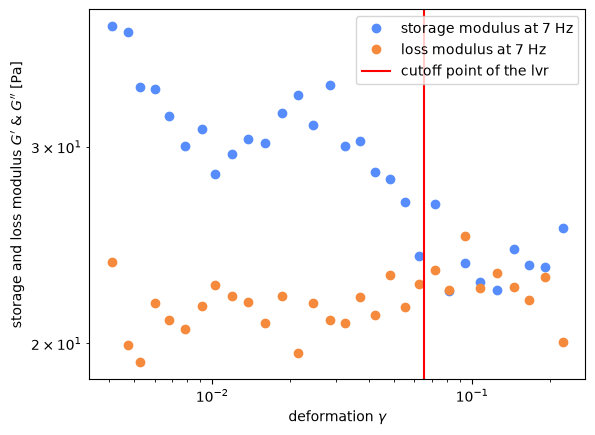

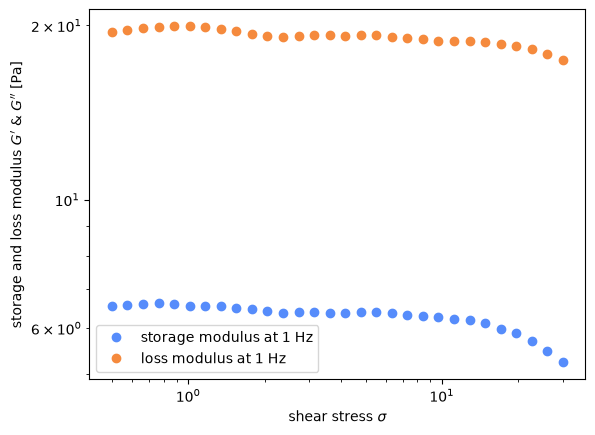

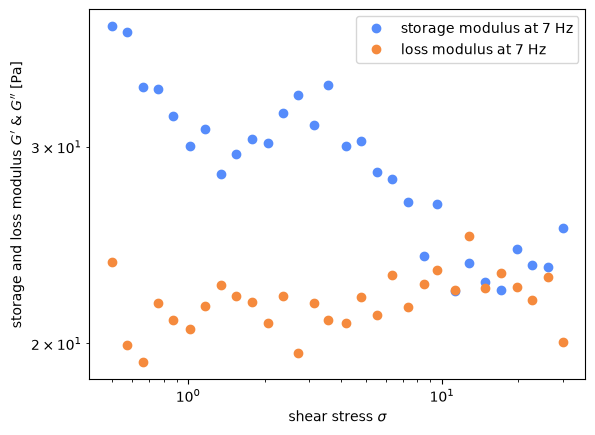

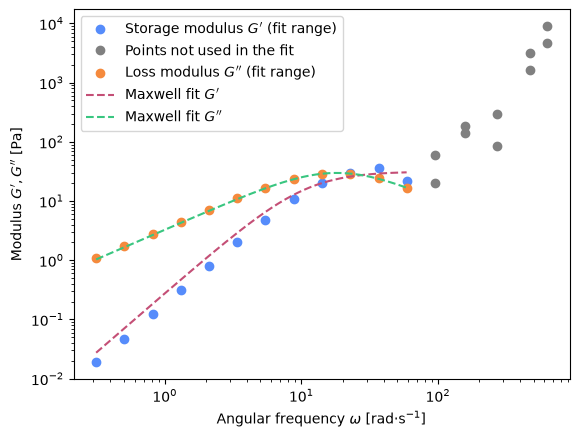

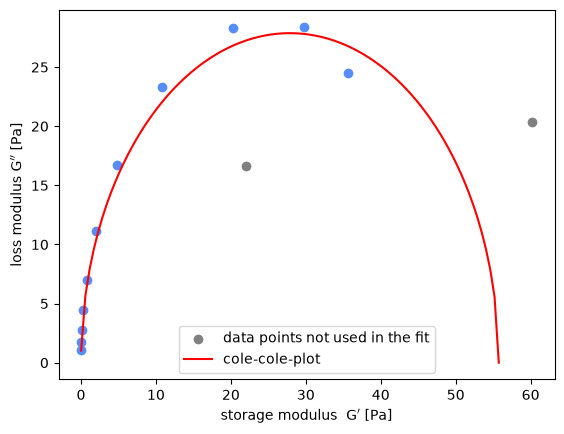

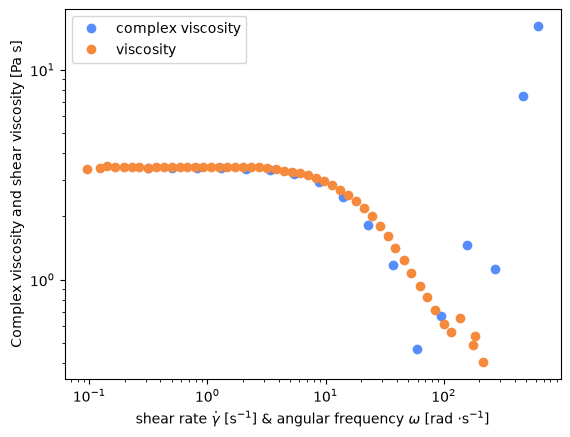

In [37]:
viskositaet_niedrigviskos = np.loadtxt("Niedrigviskos-250-viskositaet.txt", encoding="latin-1", skiprows=1, unpack=True)

scherviskos = viskositaet_niedrigviskos[2]
scherrate = viskositaet_niedrigviskos[0]

a(scherrate, scherviskos, filename="low_viscosity_fit")
n_deform_1, n_schubspannung_1, n_g1_1, n_g2_1 = np.loadtxt("Niedrigviskos-250-1hz.txt", encoding="latin1", skiprows=1,
                                                           usecols=[9, 8, 4, 5], unpack=True)
n_deform_7, n_schubspannung_7, n_g1_7, n_g2_7 = np.loadtxt("Niedrigviskos-7hz-250.txt", encoding="latin1", skiprows=1,
                                                           usecols=[9, 8, 4, 5], unpack=True)

# Zeit s	Temperatur °C	Frequenz Hz	Komp. Schubmodul Pa	Elastischer Modul Pa	Viskoser Modul Pa	Komplexe Viskosität Pas	Phasenwinkel °	Schubspannung Pa	Deformation   	Summierte Zeit s	Eta'' Pas	Dynamische Viskosität Pas	Hinweis

b(n_deform_1, n_deform_7, n_schubspannung_1, n_schubspannung_7, n_g1_1, n_g2_1, n_g1_7, n_g2_7, [0.65, 0.065],
  filename="low_viscosity_moduli")

n_oszilla = np.loadtxt("Niedrigviskos-250-oszillation.txt", encoding="latin-1", skiprows=1, unpack=True,
                       usecols=range(0, 13))
frequenz = n_oszilla[2]
g1 = n_oszilla[4]
g2 = n_oszilla[5]
c(frequenz, g1, g2, 12, filename="low_viscosity_maxwell_fit")

g1 = n_oszilla[4][:11]
g2 = n_oszilla[5][:11]

d(g1, g2, n_oszilla[4][11:13], n_oszilla[5][11:13], filename="low_viscosity_cole_cole")

n_oszilla = np.loadtxt("Niedrigviskos-250-oszillation.txt", encoding="latin-1", skiprows=1, unpack=True,
                       usecols=range(0, 13))
cvisk = n_oszilla[6]
freq = n_oszilla[2]

viskositaet_niedrigviskos = np.loadtxt("Niedrigviskos-250-viskositaet.txt", encoding="latin-1", skiprows=1, unpack=True)

scherviskos = viskositaet_niedrigviskos[2]
scherrate = viskositaet_niedrigviskos[0]

ax = plot_loglog(2 * pi * freq, cvisk, "Kreisfreq", "Kompvisk", label="complex viscosity")
plot_loglog(scherrate, scherviskos,
            r"shear rate $\dot \gamma$ [s$^{-1}$] & angular frequency $\omega$ [rad $\cdot$s$^{-1}$]",
            "Complex viscosity and shear viscosity [Pa s]",
            ax=ax, label="viscosity")
save_plot(ax.figure, "low_viscosity_complex_viscosity")

[ 1.18177791  0.38559811 27.07871699  0.35481083] [0.07496669 0.0210182  0.13851795 0.20349481]
Saved a figure

 Nullscher: 27.078716986930427
 kappa 0.38559811436292063
Saved a figure
Saved a figure
Saved a figure
Saved a figure
Saved a figure
[0.08320471 2.49409749]

Independent Maxwell fits
------------------------
G':  tau = 0.58404 +- 0.08320s, G0 = 50.745  +- 2.49410 Pa, eta0 = 29.637 Pa s
G'': tau = 0.45813  +- 0.01513s, G0 = 60.304 Pa +- 1.13380, eta0 = 27.627 Pa s

G0 cole 58.59210511260376 [0.26724247]
Saved a figure


/tmp/ipykernel_19604/961250942.py:2: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(g1 * (g0 - g1))


Saved a figure


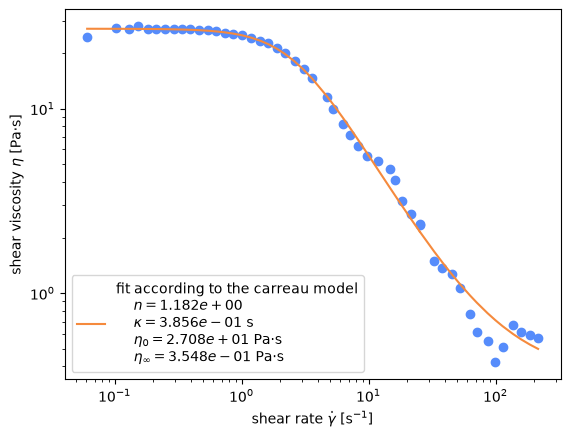

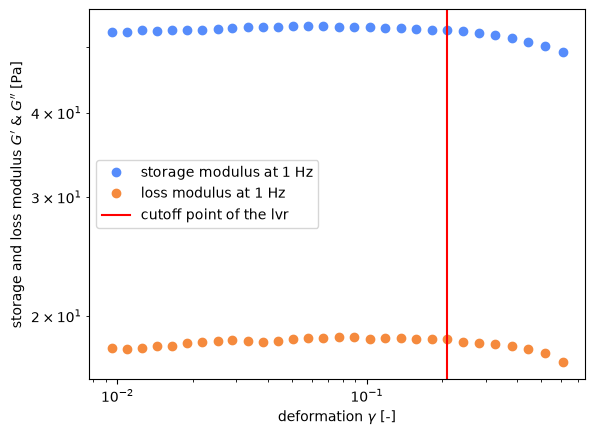

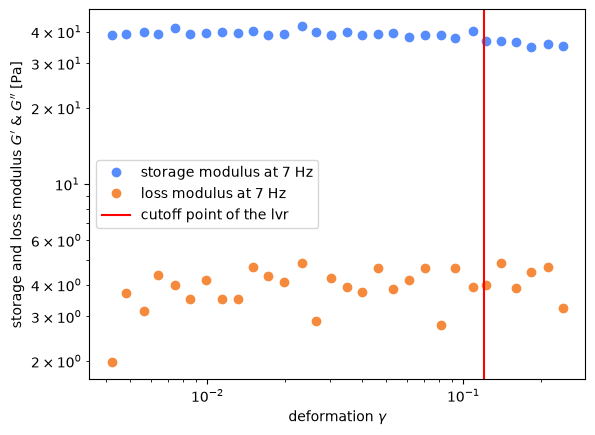

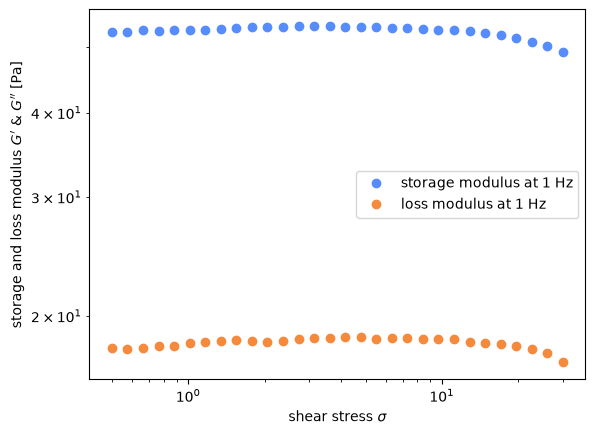

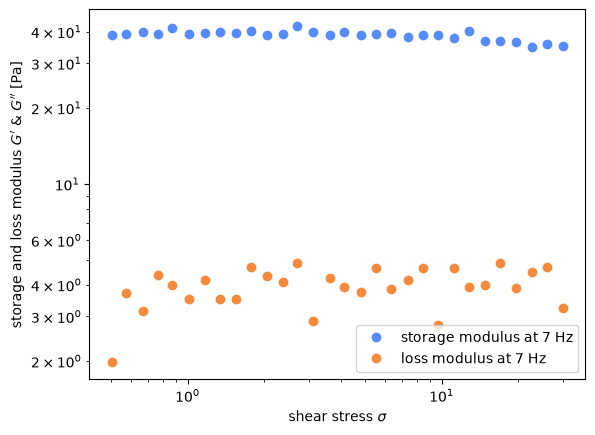

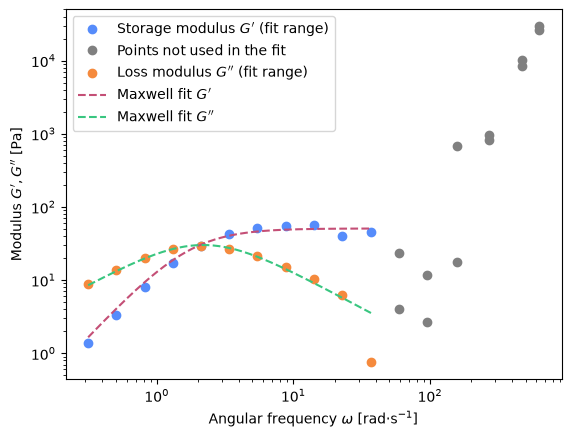

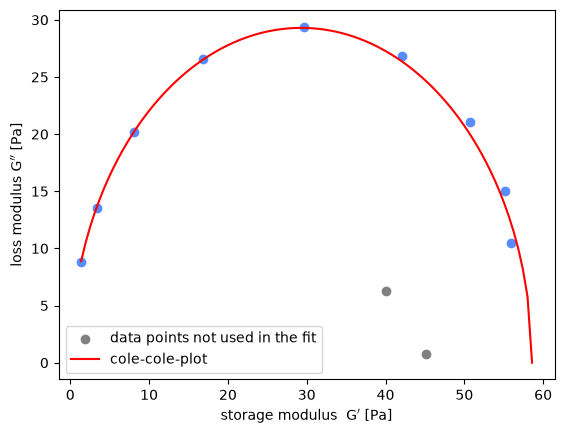

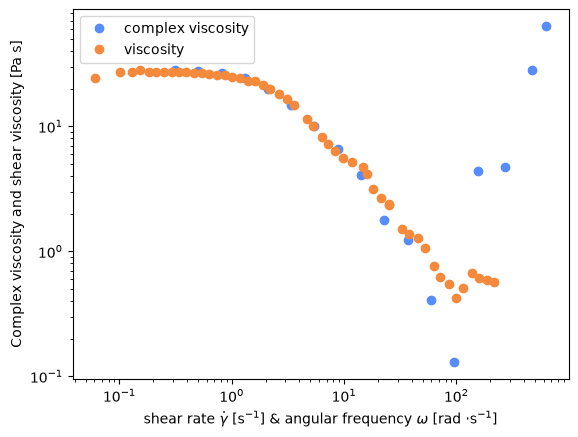

In [39]:
hochvisk_viskos = np.loadtxt("Hochviskos-viskositaet.txt", encoding="latin-1", skiprows=1, unpack=True)

scherviskos = hochvisk_viskos[2]
scherrate = hochvisk_viskos[0]

a(scherrate, scherviskos, filename="high_viscosity_fit")

h_deform_1, h_schubspannung_1, h_g1_1, h_g2_1 = np.loadtxt("Hochviskos-1hz.txt", encoding="latin1", skiprows=1,
                                                           usecols=[9, 8, 4, 5], unpack=True)
h_deform_7, h_schubspannung_7, h_g1_7, h_g2_7 = np.loadtxt("Hochviskos-7hz-richtig.txt", encoding="latin1", skiprows=1,
                                                           usecols=[9, 8, 4, 5], unpack=True)

# Zeit s	Temperatur °C	Frequenz Hz	Komp. Schubmodul Pa	Elastischer Modul Pa	Viskoser Modul Pa	Komplexe Viskosität Pas	Phasenwinkel °	Schubspannung Pa	Deformation   	Summierte Zeit s	Eta'' Pas	Dynamische Viskosität Pas	Hinweis

b(h_deform_1, h_deform_7, h_schubspannung_1, h_schubspannung_7, h_g1_1, h_g2_1, h_g1_7, h_g2_7, [.21, .12],
  filename="high_viscosity_moduli")

h_oszilla = np.loadtxt("Hochviskos-oszillation.txt", encoding="latin-1", skiprows=1, unpack=True, usecols=range(0, 13))
frequenz = h_oszilla[2]
g1 = h_oszilla[4]
g2 = h_oszilla[5]
c(frequenz, g1, g2, 11, filename="high_viscosity_maxwell_fit")
g1 = h_oszilla[4][0:9]
g2 = h_oszilla[5][0:9]

d(g1, g2, h_oszilla[4][9:11], h_oszilla[5][9:11], filename="high_viscosity_cole_cole")
g1
cvisk = h_oszilla[6]
freq = h_oszilla[2]

scherviskos = hochvisk_viskos[2]
scherrate = hochvisk_viskos[0]

ax = plot_loglog(2 * pi * freq, cvisk, "Kreisfreq", "Kompvisk", label="complex viscosity")
plot_loglog(scherrate, scherviskos,
            r"shear rate $\dot \gamma$ [s$^{-1}$] & angular frequency $\omega$ [rad $\cdot$s$^{-1}$]",
            "Complex viscosity and shear viscosity [Pa s]",
            ax=ax, label="viscosity")
save_plot(ax.figure, "high_viscosity_complex_viscosity")